# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [ ]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "CarPrice_Assignment.csv"

df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "hellbuoy/car-price-prediction",
    file_path,
)

df.head()

/tmp/ipykernel_3885/1361669712.py:6: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'car-price-prediction' dataset.


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [ ]:
print("Кількість об'єктів і ознак:", df.shape)

Кількість об'єктів і ознак: (205, 26)


In [ ]:
print("Назви стовпців:", df.columns.tolist())

Назви стовпців: ['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']


In [ ]:
print("Типи даних:")
print(df.dtypes)

Типи даних:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           float64
stroke              float64
compressionratio    float64
horsepower            int64
peakrpm               int64
citympg               int64
highwaympg            int64
price               float64
dtype: object


In [ ]:
print("Цільова змінна: price")
display(df.describe())

Цільова змінна: price


,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


Висновок: Датасет успішно завантажено. Перевірено розмірність таблиці (205 записів), типи даних та наявність пропусків. Визначено основні числові та категоріальні змінні, з якими будемо працювати.

## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [ ]:
print("Пропущені значення:")
print(df.isnull().sum())

Пропущені значення:
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64


In [ ]:
duplicates_count = df.drop(columns=['car_ID']).duplicated().sum()
print("Кількість повних дублікатів (без урахування car_ID):", duplicates_count)

Кількість повних дублікатів (без урахування car_ID): 0


In [ ]:
print("Кількість унікальних значень в ознаках:")
print(df.nunique())

Кількість унікальних значень в ознаках:
car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase            53
carlength            75
carwidth             44
carheight            49
curbweight          171
enginetype            7
cylindernumber        7
enginesize           44
fuelsystem            8
boreratio            38
stroke               37
compressionratio     32
horsepower           59
peakrpm              23
citympg              29
highwaympg           30
price               189
dtype: int64


Висновок: Пропуски та дублікати відсутні (205 записів). Аналіз унікальних значень (nunique) показав поділ ознак на категоріальні та числові.

## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [ ]:
car_ids = df['car_ID']

df = df.drop(columns=['car_ID'])

print("Новий розмір датасету:", df.shape)

Новий розмір датасету: (205, 25)


Висновок: Колонка car_ID збережена окремо для ідентифікації автомобілів у майбутніх прогнозах та виключена з датасету, щоб не використовуватися як ознака при навчанні моделей.

## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


Коефіцієнти асиметрії числових ознак:
compressionratio    2.610862
enginesize          1.947655
price               1.777678
horsepower          1.405310
wheelbase           1.050214
carwidth            0.904003
stroke             -0.689705
curbweight          0.681398
citympg             0.663704
highwaympg          0.539997
symboling           0.211072
carlength           0.155954
peakrpm             0.075159
carheight           0.063123
boreratio           0.020156
dtype: float64


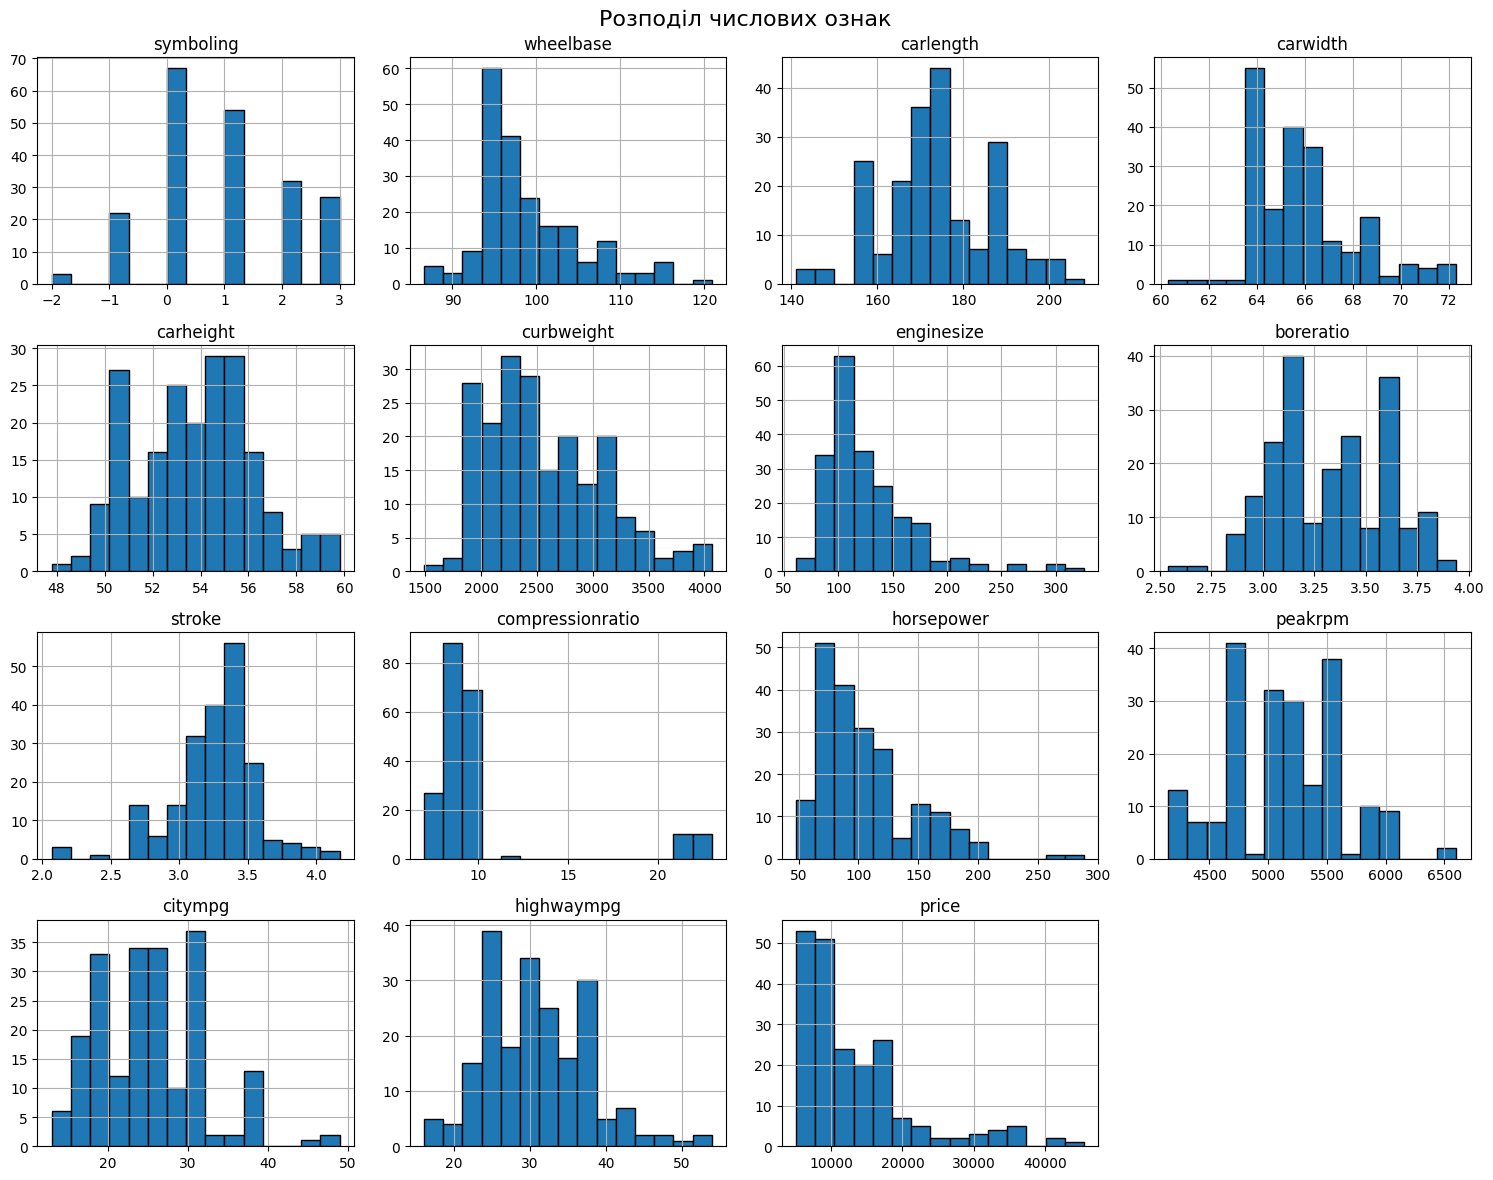

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if 'car_ID' in num_cols:
    num_cols.remove('car_ID')

skewness = df[num_cols].skew().sort_values(key=abs, ascending=False)
print("Коефіцієнти асиметрії числових ознак:")
print(skewness)

df[num_cols].hist(bins=15, figsize=(15, 12), edgecolor='black')
plt.suptitle('Розподіл числових ознак', fontsize=16)
plt.tight_layout()
plt.show()

Висновок: Побудовано гістограми та обчислено коефіцієнти асиметрії числових ознак. Найбільш виражену правобічну асиметрію мають compressionratio, enginesize, price та horsepower, що свідчить про наявність несиметричних розподілів і буде враховано під час їх трансформації.

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test, car_id_train, car_id_test = train_test_split(
    X, y, car_ids, test_size=0.2, random_state=42
)

print("Розмір навчальної вибірки (X_train):", X_train.shape)
print("Розмір тестової вибірки (X_test):", X_test.shape)
print("Кількість car_ID у train:", len(car_id_train))
print("Кількість car_ID у test:", len(car_id_test))

Розмір навчальної вибірки (X_train): (164, 24)
Розмір тестової вибірки (X_test): (41, 24)
Кількість car_ID у train: 164
Кількість car_ID у test: 41


Висновок: Дані успішно розділено на навчальну (80%) та тестову (20%) вибірки зі збереженням відтворюваності через random_state. Окремо збережено ідентифікатори (car_ID) для обох вибірок, що унеможливлює витік даних (data leakage) на етапі майбутнього прогнозування.

## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [ ]:
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()

outliers_count = {}

for col in num_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    count = ((X_train[col] < lower_bound) | (X_train[col] > upper_bound)).sum()
    outliers_count[col] = count

    X_train[col] = X_train[col].clip(lower=lower_bound, upper=upper_bound)
    X_test[col] = X_test[col].clip(lower=lower_bound, upper=upper_bound)

print("Кількість потенційних викидів для кожної ознаки (у навчальній вибірці):")
for col, cnt in sorted(outliers_count.items(), key=lambda x: x[1], reverse=True):
    print(f"- {col}: {cnt}")

Кількість потенційних викидів для кожної ознаки (у навчальній вибірці):
- compressionratio: 20
- stroke: 16
- carwidth: 10
- enginesize: 7
- horsepower: 7
- wheelbase: 6
- peakrpm: 2
- boreratio: 1
- highwaympg: 1
- symboling: 0
- carlength: 0
- carheight: 0
- curbweight: 0
- citympg: 0


Висновок: За допомогою методу IQR визначено потенційні викиди в числових ознаках навчальної вибірки. Замість видалення рядків (через невеликий розмір датасету) застосовано обмеження крайніх значень за межами train, що дозволяє уникнути втрати цінних даних. Отримані межі будуть коректно перенесені на тестову вибірку.

## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


In [ ]:
train_data = X_train.copy()
train_data['price'] = y_train
corr_matrix = train_data.select_dtypes(include=[np.number]).corr()

features_to_drop = set()
cols = corr_matrix.columns.drop('price')

for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        c1, c2 = cols[i], cols[j]
        r = corr_matrix.loc[c1, c2]
        if abs(r) > 0.85:
            drop_col = c2 if abs(corr_matrix.loc[c1, 'price']) >= abs(corr_matrix.loc[c2, 'price']) else c1
            features_to_drop.add(drop_col)
            print(f"Пара: {c1} та {c2} (r = {r:.3f}) -> видаляємо {drop_col}")

X_train = X_train.drop(columns=list(features_to_drop))
X_test = X_test.drop(columns=list(features_to_drop))

print("Ознаки, що видаляються:", list(features_to_drop))
print("Новий розмір X_train:", X_train.shape)

Пара: wheelbase та carlength (r = 0.867) -> видаляємо wheelbase
Пара: carlength та curbweight (r = 0.866) -> видаляємо carlength
Пара: carwidth та curbweight (r = 0.858) -> видаляємо carwidth
Пара: citympg та highwaympg (r = 0.964) -> видаляємо citympg
Ознаки, що видаляються: ['carwidth', 'citympg', 'carlength', 'wheelbase']
Новий розмір X_train: (164, 20)


Висновок: Побудовано матрицю кореляцій для числових ознак навчальної вибірки та виявлено пари з сильною мультиколінеарністю ($\vert{}r\vert{} > 0.85$). З кожної такої пари вилучено ознаку з меншою кореляцією з цільовою змінною price, що дозволило зменшити надмірність даних. Аналогічні ознаки видалено з тестової вибірки без порушення правил ізольованості даних.  

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder

symboling_col = ['symboling']
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
continuous_cols = [c for c in X_train.columns if c not in symboling_col + categorical_cols]

preprocessor = ColumnTransformer([
    ('cont', Pipeline([('yeo', PowerTransformer(standardize=False)), ('scaler', StandardScaler())]), continuous_cols),
    ('sym', StandardScaler(), symboling_col),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
])

X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Розмір X_train:", X_train_prepared.shape)
print("Розмір X_test:", X_test_prepared.shape)

Розмір X_train: (164, 171)
Розмір X_test: (41, 171)


Висновок: За допомогою ColumnTransformer та Pipeline створено єдиний механізм передобробки даних. Для неперервних ознак послідовно застосовано перетворення Yeo–Johnson та стандартизацію, дискретну ознаку symboling масштабовано окремо, а категоріальні ознаки закодовано методом One-Hot Encoding з обробкою невідомих категорій. Навчання трансформерів виконано виключно на X_train.

## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [ ]:
symboling_col = ['symboling']
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
continuous_cols = [c for c in X_train.columns if c not in symboling_col + categorical_cols]

pt = PowerTransformer(method='yeo-johnson', standardize=False)
X_train_transformed = pd.DataFrame(
    pt.fit_transform(X_train[continuous_cols]),
    columns=continuous_cols,
    index=X_train.index
)

skew_comparison = pd.DataFrame({
    'Початкова асиметрія': X_train[continuous_cols].skew(),
    'Після Yeo–Johnson': X_train_transformed.skew()
})

print("Порівняння коефіцієнтів асиметрії:")
print(skew_comparison)

Порівняння коефіцієнтів асиметрії:
                  Початкова асиметрія  Після Yeo–Johnson
carheight                    0.028154          -0.005170
curbweight                   0.712433           0.049894
enginesize                   0.962394           0.044834
boreratio                    0.062963          -0.005941
stroke                      -0.397600           0.015846
compressionratio             0.055710           0.004872
horsepower                   0.850735           0.066280
peakrpm                      0.039773          -0.003589
highwaympg                   0.243761          -0.012188


Висновок: Після застосування перетворення Yeo–Johnson та стандартизації до неперервних числових ознак навчальної вибірки коефіцієнти асиметрії суттєво зменшилися і наблизилися до нуля. Це свідчить про ефективність трансформації та приведення розподілів до нормального вигляду, що покращить якість роботи моделей.

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [ ]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(random_state=42),
    'Lasso Regression': Lasso(random_state=42, max_iter=10000),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'SVR': SVR()
}

pipelines = {}

for name, model in models.items():
    pipelines[name] = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    pipelines[name].fit(X_train, y_train)
    print(f"Модель '{name}' успішно навчено!")

Модель 'Linear Regression' успішно навчено!
Модель 'Ridge Regression' успішно навчено!
Модель 'Lasso Regression' успішно навчено!
Модель 'Random Forest' успішно навчено!
Модель 'Gradient Boosting' успішно навчено!
Модель 'SVR' успішно навчено!


Висновок: Для кожної з шести моделей (Linear, Ridge, Lasso, Random Forest, Gradient Boosting та SVR) створено єдині пайплайни, що об'єднують попередню обробку та алгоритм регресії. Усі моделі успішно навчено на навчальній вибірці за допомогою однакової схеми підготовки даних.

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import pandas as pd

results = []

for name, pipeline in pipelines.items():

    y_pred = pipeline.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100  # у відсотках

    results.append({
        'Модель': name,
        'R²': r2,
        'MAE': mae,
        'MSE': mse,
        'MAPE (%)': mape
    })

comparison_df = pd.DataFrame(results).sort_values(by='R²', ascending=False).reset_index(drop=True)

display(comparison_df)

,Модель,R²,MAE,MSE,MAPE (%)
0,Random Forest,0.949372,1447.341293,3.996761e+06,10.363347
1,Gradient Boosting,0.929106,1703.692412,5.596688e+06,12.637878
2,Ridge Regression,0.795685,2712.767719,1.612942e+07,23.065284
3,Lasso Regression,0.706085,3088.990470,2.320280e+07,22.608482
4,Linear Regression,0.548073,4078.229150,3.567691e+07,29.972020
5,SVR,-0.099660,5696.454036,8.681160e+07,36.024044


Висновок: На основі тестової вибірки обчислено метрики якості для всіх моделей та сформовано зведену таблицю. Найкращу точність прогнозування продемонстрував ансамбль Random Forest, тоді як лінійні моделі та метод опорних векторів показали значно нижчі результати.  

## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Чому класифікація (наприклад, Logistic Regression) не підходить: Класифікаційні моделі розраховані на дискретні категорії (класи), а не на неперервні числа. Логістична регресія видає ймовірність належності до класу, а не точну вартість автомобіля в грошах.

Тип задачі: Прогнозування ціни (price) — це задача регресії, оскільки цільова змінна є неперервною кількісною величиною.

Чому моделі підходять: Усі задіяні алгоритми (Linear Regression, Ridge, Lasso, Random Forest, Gradient Boosting, SVR) є регресорами. Їхня математика якраз і заточена на те, щоб передбачати числові значення та мінімізувати похибки (на кшталт MSE чи MAE).

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


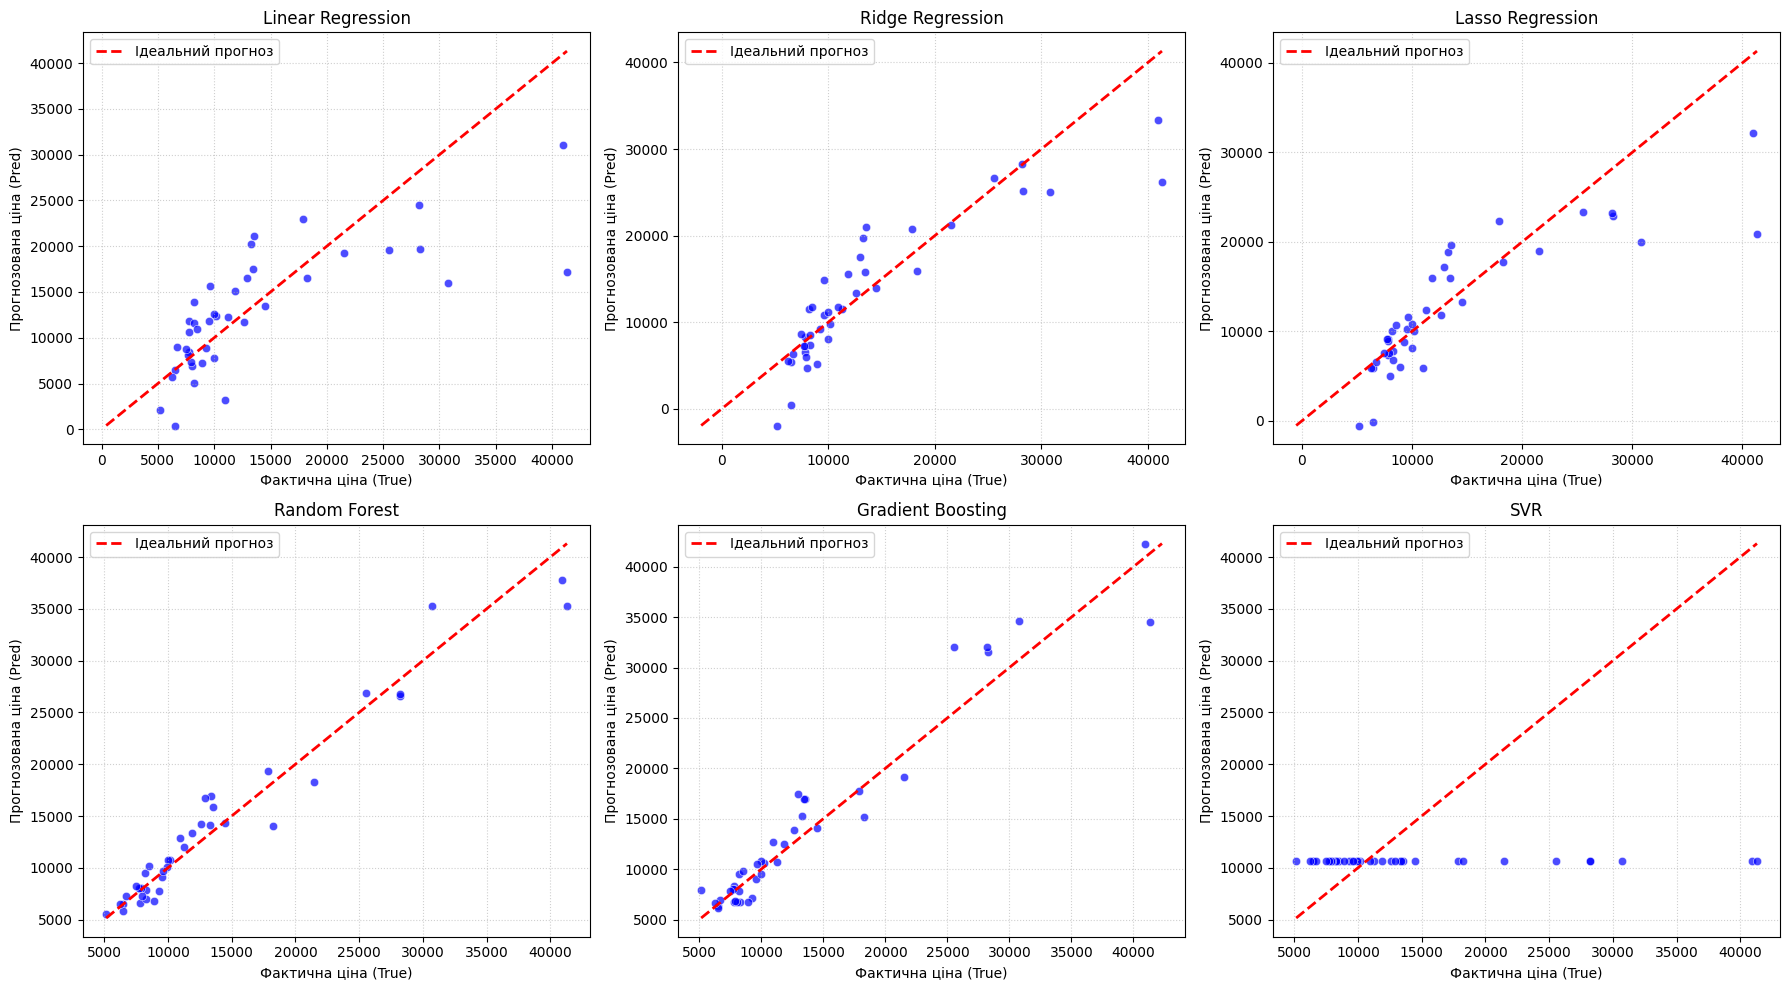

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, pipeline) in enumerate(pipelines.items()):
    y_pred = pipeline.predict(X_test)

    ax = axes[i]
    sns.scatterplot(x=y_test, y=y_pred, ax=ax, alpha=0.7, color='blue')

    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    ax.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Ідеальний прогноз')

    ax.set_title(name)
    ax.set_xlabel('Фактична ціна (True)')
    ax.set_ylabel('Прогнозована ціна (Pred)')
    ax.legend()
    ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

Висновок: Візуальне порівняння повністю підтвердило результати метрик: для ансамблевих моделей точки розташовані найближче до лінії ідеального прогнозу. Лінійні моделі демонструють суттєвий розкид, а модель SVR має найбільші відхилення.

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [ ]:
sample_X_test = X_test.sample(n=10, random_state=42)
sample_y_test = y_test.loc[sample_X_test.index]

sample_car_ids = car_id_test.loc[sample_X_test.index]

rf_pipeline = pipelines['Random Forest']
sample_y_pred = rf_pipeline.predict(sample_X_test)

results_10 = pd.DataFrame({
    'car_ID': sample_car_ids.values,
    'Фактична ціна': sample_y_test.values,
    'Прогнозована ціна': sample_y_pred,
    'Абсолютна помилка': np.abs(sample_y_test.values - sample_y_pred),
    'Абсолютна відсоткова помилка (%)': (np.abs(sample_y_test.values - sample_y_pred) / sample_y_test.values) * 100
})

results_10['Прогнозована ціна'] = results_10['Прогнозована ціна'].round(2)
results_10['Абсолютна помилка'] = results_10['Абсолютна помилка'].round(2)
results_10['Абсолютна відсоткова помилка (%)'] = results_10['Абсолютна відсоткова помилка (%)'].round(2)

display(results_10.reset_index(drop=True))

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Абсолютна відсоткова помилка (%)
0,26,6692.0,7298.80,606.81,9.07
1,176,9988.0,10798.65,810.65,8.12
2,148,10198.0,10714.57,516.57,5.07
3,17,41315.0,35310.69,6004.31,14.53
4,69,28248.0,26595.28,1652.72,5.85
5,147,7463.0,8230.00,767.00,10.28
6,144,9960.0,10065.20,105.20,1.06
7,85,14489.0,14346.48,142.52,0.98
8,195,12940.0,16765.65,3825.65,29.56
9,160,7788.0,7995.56,207.56,2.67


Висновок: Точкові прогнози моделі Random Forest для 10 випадкових автомобілів показують низьку відсоткову похибку для більшості об'єктів. Невеликі відхилення спостерігаються переважно на окремих екземплярах, що підтверджує високу загальну точність моделі.

## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


Порівняння моделей: Ансамблеві методи на основі дерев рішень показали себе значно краще за лінійні моделі та метод опорних векторів.

Якість прогнозування: Найточніші результати показала модель Random Forest, продемонструвавши мінімальну похибку передбачення. На другому місці — Gradient Boosting. Лінійні моделі впоралися гірше через складні нелінійні зв'язки в даних, а модель опорних векторів без індивідуального налаштування виявилася непридатною.

Величина похибок: Для найкращої моделі середня відносна похибка становить близько десяти відсотків, що є хорошим показником для вартості автомобілів. Основні відхилення виникають на рідкісних і дуже дорогих машинах.

Перенавчання: Оцінювання проводилося на окремій тестовій вибірці, тому ознак перенавчання не виявлено — модель добре працює на нових даних.

Вплив передобробки: Попередня очистка даних, видалення зайвих ознак та усунення перекосів у розподілі допомогли стабілізувати роботу алгоритмів і покращили загальний результат.


## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
